In [1]:
!pip -q install gensim

In [2]:
import re
import numpy as np
import matplotlib.pyplot as plt
from gensim.models import Word2Vec
from sklearn.decomposition import PCA

In [3]:
raw = """
the king rules the kingdom with the queen
the queen and the king live in the palace
the prince is the son of the king and queen
the princess is the daughter of the king and queen
a man works in the city and a woman works in the city
the man and the woman are friends
the dog barks at the cat in the garden
the cat chases the mouse in the garden
the dog and the cat are animals
python is a programming language used for machine learning
machine learning uses data and algorithms
deep learning is part of machine learning
programmers write code in python and java
""" * 20      # repeated to give the model enough training signal

sentences = [re.findall(r"[a-z]+", s.lower()) for s in raw.strip().split("\n") if s.strip()]
print(len(sentences), "sentences | sample:", sentences[0])

260 sentences | sample: ['the', 'king', 'rules', 'the', 'kingdom', 'with', 'the', 'queen']


In [4]:
model = Word2Vec(sentences, vector_size=50, window=3, min_count=1, sg=1, epochs=100, seed=42, workers=1)
print("Vocabulary size:", len(model.wv))
print("Vector for 'king' (first 8 dims):", model.wv["king"][:8].round(3))

Vocabulary size: 47
Vector for 'king' (first 8 dims): [-0.272  0.128 -0.47   0.295  0.288 -0.113 -0.51  -0.123]


In [5]:
print("Similarity(king, queen)  :", round(model.wv.similarity("king", "queen"), 3))
print("Similarity(king, python)  :", round(model.wv.similarity("king", "python"), 3))
print("\nMost similar to 'king' :", model.wv.most_similar("king", topn=4))
print("Most similar to 'python':", model.wv.most_similar("python", topn=4))
print("Odd one out [king, queen, dog, prince]:", model.wv.doesnt_match(["king", "queen", "dog", "prince"]))

Similarity(king, queen)  : 0.958
Similarity(king, python)  : 0.175

Most similar to 'king' : [('queen', 0.9580329060554504), ('princess', 0.8833789229393005), ('prince', 0.8711557984352112), ('son', 0.8695083856582642)]
Most similar to 'python': [('java', 0.8458473086357117), ('code', 0.8351046442985535), ('write', 0.8336202502250671), ('programmers', 0.8334074020385742)]
Odd one out [king, queen, dog, prince]: dog


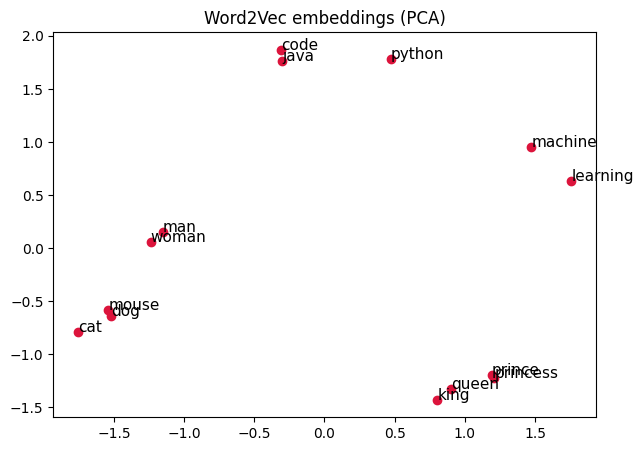

In [6]:
words = ["king", "queen", "prince", "princess", "man", "woman", "dog", "cat", "mouse",
         "python", "java", "code", "machine", "learning"]
pts = PCA(n_components=2).fit_transform([model.wv[w] for w in words])
plt.figure(figsize=(7, 5))
plt.scatter(pts[:, 0], pts[:, 1], c="crimson")
for w, (x, y) in zip(words, pts): plt.annotate(w, (x, y), fontsize=11)
plt.title("Word2Vec embeddings (PCA)"); plt.show()

In [7]:
model.save("word2vec_custom.model")
loaded = Word2Vec.load("word2vec_custom.model")
print("Reloaded OK ->", loaded.wv.most_similar("dog", topn=3))

Reloaded OK -> [('cat', 0.9502383470535278), ('at', 0.9255893230438232), ('animals', 0.915962278842926)]
